In [1]:
# ==============================================================================
# CELL 0: IMPORTS & CONFIGURATION
# ==============================================================================
import os
import glob
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

def matplotlib_default_config():
    font = {'family': 'serif', 'weight': 'normal', 'size': 14}
    rcnew = {
        "mathtext.fontset": "cm",
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize": 20,
        "axes.labelsize": 20,
        "legend.fontsize": 12,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'xtick.top': True,
        'ytick.right': True,
        'xtick.labelsize': 18,
        'ytick.labelsize': 18,
    }
    return font, rcnew

%matplotlib widget
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

In [2]:
# ==============================================================================
# CELL 1: LOAD ALL SIMULATIONS (TNG50-2, 3, 4) — 5 RUNS EACH
# ==============================================================================
HUBBLE_H = 0.6774
MASS_CONVERSION_FACTOR = 1e10 / HUBBLE_H

# --- Simulation definitions ---
SIM_CONFIGS = {
     'TNG50-2': {
         'data_dir': 'data_for_variance_50_2_mask',
         'pattern': 'TNG50-2_z3_*_DLAMode_Stratified_run*.pkl',
         'color': 'tab:blue',
         'ls': '-',
         'label': 'TNG50-2 (High Res)',
    },
    'TNG50-3': {
        'data_dir': 'data_for_variance_50_3_mask',
        'pattern': 'TNG50-3_z3_*_DLAMode_Stratified_run*.pkl',
        'color': 'tab:orange',
        'ls': '--',
        'label': 'TNG50-3',
    },
    'TNG50-4': {
        'data_dir': 'data_for_variance_50_4_mask',
        'pattern': 'TNG50-4_z3_*_DLAMode_Stratified_run*.pkl',
        'color': 'tab:green',
        'ls': ':',
        'label': 'TNG50-4',
    },
}

# --- Load runs for each simulation ---
sim_data = {}  # key: sim_name -> list of DataFrames (one per run)

for sim_name, cfg in SIM_CONFIGS.items():
    data_dir = cfg['data_dir']
    pattern  = os.path.join(data_dir, cfg['pattern'])
    files    = sorted(glob.glob(pattern))
    
    # Exclude any "Extended_" files
    files = [f for f in files if 'Extended_' not in os.path.basename(f)]

    if len(files) == 0:
        print(f"  [!] WARNING: No files found for {sim_name} in {data_dir}. Skipping.")
        continue

    runs = []
    for rf in files:
        df = pd.read_pickle(rf)
        df['r_mult_round']  = df['r_multiplier'].round(2)
        df['halo_mass_msun'] = df['halo_mass'] * MASS_CONVERSION_FACTOR
        runs.append(df)

    sim_data[sim_name] = runs
    print(f"{sim_name}: {len(runs)} runs loaded "
          f"({[len(r) for r in runs]} rows each)")

# --- Determine common impact parameters (union across sims) ---
all_radii_sets = []
for sim_name, runs in sim_data.items():
    for df_run in runs:
        all_radii_sets.append(set(df_run['r_mult_round'].unique()))

# Use the radii from the first simulation's first run as reference
ref_sim   = list(sim_data.keys())[0]
ref_radii = np.sort(sim_data[ref_sim][0]['r_mult_round'].unique())
print(f"\nReference impact parameters from {ref_sim} ({len(ref_radii)}):")
print(f"  {ref_radii}")

n_sims = len(sim_data)
print(f"\n{n_sims} simulations loaded successfully.")

TNG50-2: 5 runs loaded ([231231, 231231, 231231, 231231, 231231] rows each)
TNG50-3: 5 runs loaded ([231231, 231231, 231231, 231231, 231231] rows each)
TNG50-4: 5 runs loaded ([231231, 231231, 231231, 231231, 231231] rows each)

Reference impact parameters from TNG50-2 (29):
  [0.000e+00 1.000e-02 2.000e-02 3.000e-02 4.000e-02 6.000e-02 8.000e-02
 1.000e-01 1.400e-01 1.900e-01 2.500e-01 3.400e-01 4.600e-01 6.100e-01
 8.200e-01 1.100e+00 1.470e+00 1.980e+00 2.650e+00 3.560e+00 4.770e+00
 6.400e+00 8.580e+00 1.151e+01 1.544e+01 2.072e+01 2.779e+01 3.728e+01
 5.000e+01]

3 simulations loaded successfully.


  Grid loaded: TNG50-2 (750,000 skewers)
  Grid loaded: TNG50-3 (750,000 skewers)
  Grid loaded: TNG50-4 (750,000 skewers)


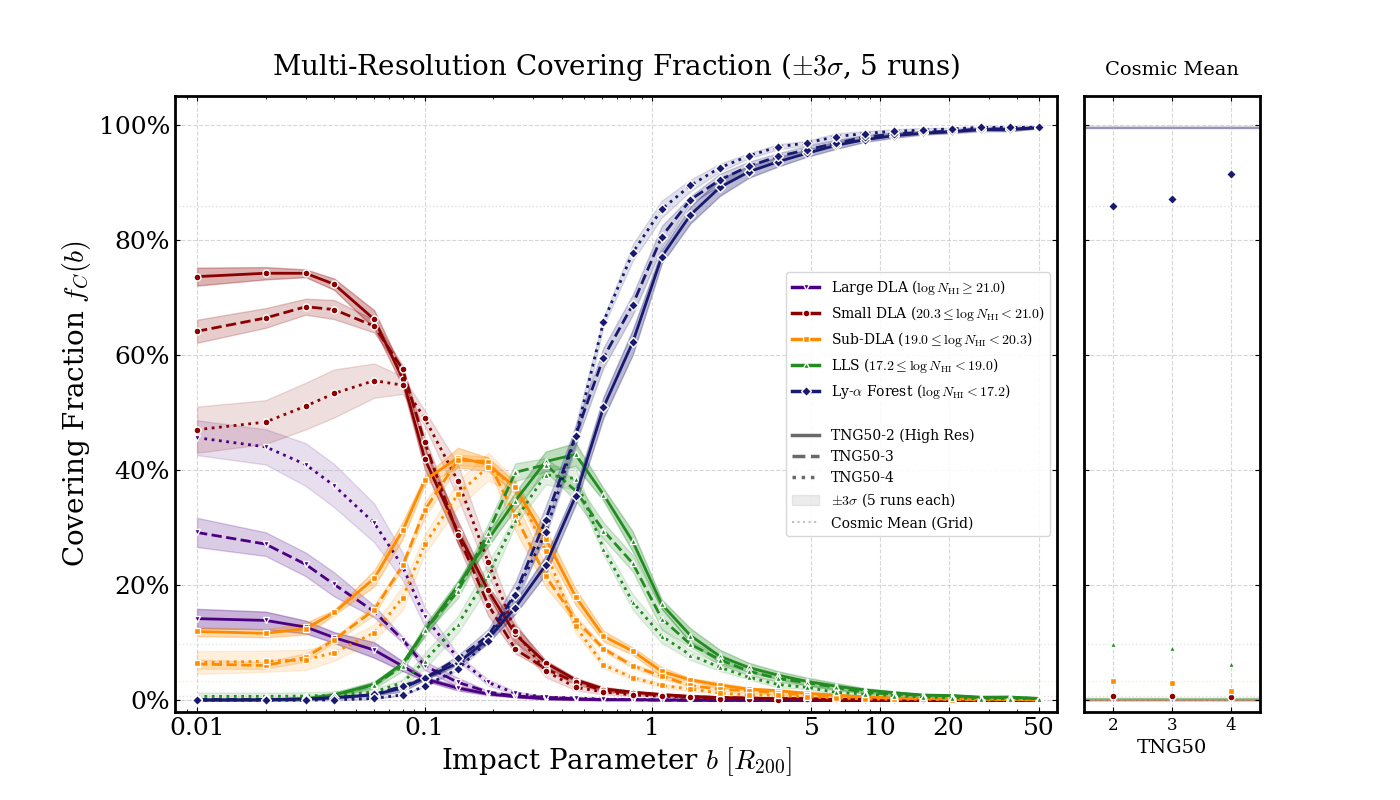

In [3]:
# ==============================================================================
# CELL 2: COVERING FRACTION — MULTI-RESOLUTION WITH GRID PANEL (b up to 50)     
# ==============================================================================
NSIGMA = 3    

cat_styles = {
    'Large_DLA': {'color': 'indigo',       'marker': 'v',
                  'label': r'Large DLA ($\log N_{\mathrm{HI}} \geq 21.0$)'},
    'Small_DLA': {'color': 'darkred',      'marker': 'o',
                  'label': r'Small DLA ($20.3 \leq \log N_{\mathrm{HI}} < 21.0$)'},
    'Sub_DLA':   {'color': 'darkorange',   'marker': 's',
                  'label': r'Sub-DLA ($19.0 \leq \log N_{\mathrm{HI}} < 20.3$)'},
    'LLS':       {'color': 'forestgreen',  'marker': '^',
                  'label': r'LLS ($17.2 \leq \log N_{\mathrm{HI}} < 19.0$)'},
    'Forest':    {'color': 'midnightblue', 'marker': 'D',
                  'label': r'Ly-$\alpha$ Forest ($\log N_{\mathrm{HI}} < 17.2$)'},
}

# --- Load Grid files (one per simulation) ---
GRID_FILES = {
    'TNG50-2': 'data_grid/TNG50-2_z3_Grid_500x500_DLAMode.pkl',
    'TNG50-3': 'data_grid/TNG50-3_z3_Grid_500x500_DLAMode.pkl',
    'TNG50-4': 'data_grid/TNG50-4_z3_Grid_500x500_DLAMode.pkl',
}

bins_grid   = [0, 1.6e17, 1e19, 2e20, 1e21, np.inf]
labels_grid = ['Forest', 'LLS', 'Sub_DLA', 'Small_DLA', 'Large_DLA']

grid_fractions = {}  # sim_name -> {cat: fraction}

for sim_name, gpath in GRID_FILES.items():
    if os.path.exists(gpath):
        df_g = pd.read_pickle(gpath)
        df_g['category'] = pd.cut(
            df_g['total_col_den'], bins=bins_grid, labels=labels_grid, right=False
        )
        total = len(df_g)
        counts = df_g['category'].value_counts(sort=False)
        grid_fractions[sim_name] = {cat: counts.get(cat, 0) / total for cat in labels_grid}
        print(f"  Grid loaded: {sim_name} ({total:,} skewers)")
    else:
        print(f"  [!] Grid file not found for {sim_name}: {gpath}")

# --- Compute fractions per run per simulation ---
def compute_fractions_per_run(runs, radii):
    fracs = {cat: [] for cat in cat_styles}
    for df_run in runs:
        run_fracs = {cat: [] for cat in cat_styles}
        for b_val in radii:
            df_b = df_run[df_run['r_mult_round'] == b_val]
            tot  = len(df_b)
            if tot > 0:
                nhi = df_b['log_n_hi']
                run_fracs['Large_DLA'].append(len(nhi[nhi >= 21.0]) / tot)
                run_fracs['Small_DLA'].append(len(nhi[(nhi >= 20.3) & (nhi < 21.0)]) / tot)
                run_fracs['Sub_DLA'].append(len(nhi[(nhi >= 19.0) & (nhi < 20.3)]) / tot)
                run_fracs['LLS'].append(len(nhi[(nhi >= 17.2) & (nhi < 19.0)]) / tot)
                run_fracs['Forest'].append(len(nhi[nhi < 17.2]) / tot)
            else:
                for cat in cat_styles:
                    run_fracs[cat].append(0.0)
        for cat in cat_styles:
            fracs[cat].append(run_fracs[cat])
    for cat in cat_styles:
        fracs[cat] = np.array(fracs[cat])
    return fracs

sim_fractions = {}
for sim_name, runs in sim_data.items():
    radii = np.sort(runs[0]['r_mult_round'].unique())
    sim_fractions[sim_name] = {
        'radii': radii,
        'fracs': compute_fractions_per_run(runs, radii),
    }

# --- Alpha Mapping for variance shading per simulation ---
alpha_map = {
    'TNG50-2': 0.30,  # Darkest shade
    'TNG50-3': 0.20,  # Intermediate shade
    'TNG50-4': 0.13,  # Lightest shade
}

# --- PLOT ---
fig_cov, (ax_main, ax_grid) = plt.subplots(
    1, 2, figsize=(14, 8),
    sharey=True,
    gridspec_kw={'width_ratios': [5, 1], 'wspace': 0.05},
)

# ---- Main panel: profiles ----
for cat, cstyle in cat_styles.items():
    for sim_name, cfg in SIM_CONFIGS.items():
        if sim_name not in sim_fractions:
            continue

        radii = sim_fractions[sim_name]['radii']
        data  = sim_fractions[sim_name]['fracs'][cat]  # (n_runs, n_radii)

        mean_f = np.mean(data, axis=0)
        std_f  = np.std(data, axis=0)

        ls = cfg['ls']
        shade_alpha = alpha_map.get(sim_name, 0.07)

        # Only positive radii for log scale
        mask   = radii > 0
        r_plot = radii[mask]
        m_plot = mean_f[mask]
        s_plot = std_f[mask]

        # ±Nσ shading
        ax_main.fill_between(
            r_plot,
            np.clip(m_plot - NSIGMA * s_plot, 0, None),
            np.clip(m_plot + NSIGMA * s_plot, None, 1),
            color=cstyle['color'], alpha=shade_alpha, zorder=1,
        )

        # Mean line
        ax_main.plot(
            r_plot, m_plot,
            color=cstyle['color'], lw=2.0, ls=ls,
            marker=cstyle['marker'], ms=5, mec='white', zorder=3,
        )

    # Cosmic-mean dotted line spanning main panel
    for sim_name in grid_fractions:
        gval = grid_fractions[sim_name].get(cat, None)
        if gval is not None:
            ax_main.axhline(gval, color=cstyle['color'], ls=':', alpha=0.15, lw=1.0, zorder=0)
            break  # just one reference line per category

# ---- Side panel: Grid cosmic means ----
x_positions = np.arange(len(grid_fractions))
x_width     = 0.8 / max(len(grid_fractions), 1)

# Map sim -> x position
sim_x_map = {sn: i for i, sn in enumerate(grid_fractions.keys())}

for cat, cstyle in cat_styles.items():
    for sim_name, gf in grid_fractions.items():
        gval = gf.get(cat, None)
        if gval is None:
            continue

        x_pos = sim_x_map[sim_name]
        cfg   = SIM_CONFIGS.get(sim_name, {})
        mkr   = cstyle['marker']

        # Segment indicating the resolution in the grid
        #ax_grid.plot(
            #[x_pos - 0.25, x_pos + 0.25], [gval, gval],
            #color=cstyle['color'], lw=2.0, ls=cfg['ls'], alpha=0.8, zorder=2
        #)

        # Marker point
        ax_grid.plot(
            x_pos, gval,
            color=cstyle['color'], marker=mkr,
            ms=5, mec='white', zorder=3,
        )

    # Extend the last skewer-run variance into the side panel
    for sim_name, cfg in SIM_CONFIGS.items():
        if sim_name not in sim_fractions:
            continue
        data = sim_fractions[sim_name]['fracs'][cat]
        last_mean = np.mean(data, axis=0)[-1]
        last_std  = np.std(data, axis=0)[-1]
        shade_alpha = alpha_map.get(sim_name, 0.07)

        ax_grid.axhspan(
            np.clip(last_mean - NSIGMA * last_std, 0, None),
            np.clip(last_mean + NSIGMA * last_std, None, 1),
            color=cstyle['color'], alpha=shade_alpha * 0.6, zorder=0,
        )

    # Dotted horizontal lines in grid panel
    for sim_name in grid_fractions:
        gval = grid_fractions[sim_name].get(cat, None)
        if gval is not None:
            ax_grid.axhline(gval, color=cstyle['color'], ls=':', alpha=0.15, lw=1.0, zorder=0)
            break

# ---- Aesthetics: main panel ----
ax_main.grid(True, ls='--', alpha=0.5)
ax_main.set_xscale('log')
ax_main.set_ylim(-0.02, 1.05)
ax_main.set_xlim(0.008, 60)
ax_main.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0))

ax_main.set_xticks([0.01, 0.1, 1.0, 5.0, 10.0, 20.0, 50.0])
ax_main.set_xticklabels(['0.01', '0.1', '1', '5', '10', '20', '50'])

ax_main.set_xlabel(r'Impact Parameter $b \ [R_{200}]$')
ax_main.set_ylabel(r'Covering Fraction $f_C(b)$')
ax_main.set_title(
    rf'Multi-Resolution Covering Fraction ($\pm{NSIGMA}\sigma$, 5 runs)',
    pad=15,
)

# ---- Aesthetics: side panel ----
ax_grid.grid(True, ls='--', alpha=0.5)
sim_names_in_grid = list(grid_fractions.keys())
ax_grid.set_xlim(-0.5, len(sim_names_in_grid) - 0.5)
ax_grid.set_xticks(list(range(len(sim_names_in_grid))))
ax_grid.set_xticklabels(
    [s.replace('TNG50-', '') for s in sim_names_in_grid],
    fontsize=12,
)
ax_grid.set_xlabel('TNG50', fontsize=14)
ax_grid.set_title('Cosmic Mean', pad=15, fontsize=14)

# ---- Composite legend ----
legend_cat = [
    Line2D([0], [0], color=c['color'], lw=2.5, marker=c['marker'],
           ms=5, mec='white', label=c['label'])
    for c in cat_styles.values()
]
legend_cat.append(Line2D([0], [0], color='none', label=' '))

legend_sim = [
    Line2D([0], [0], color='dimgray', lw=2.5, ls=cfg['ls'],
           label=cfg['label'])
    for sim_name, cfg in SIM_CONFIGS.items()
    if sim_name in sim_data
]

legend_sim.append(
    patches.Patch(facecolor='gray', alpha=0.15, edgecolor='gray',
                  label=rf'$\pm {NSIGMA}\sigma$ (5 runs each)')
)
legend_sim.append(
    Line2D([0], [0], color='gray', ls=':', alpha=0.5, lw=1.5,
           label='Cosmic Mean (Grid)')
)

ax_main.legend(
    handles=legend_cat + legend_sim, loc='center right',
    frameon=True, fontsize=10, edgecolor='lightgray',
    facecolor='white', framealpha=0.9,
)

#plt.tight_layout()
plt.show()

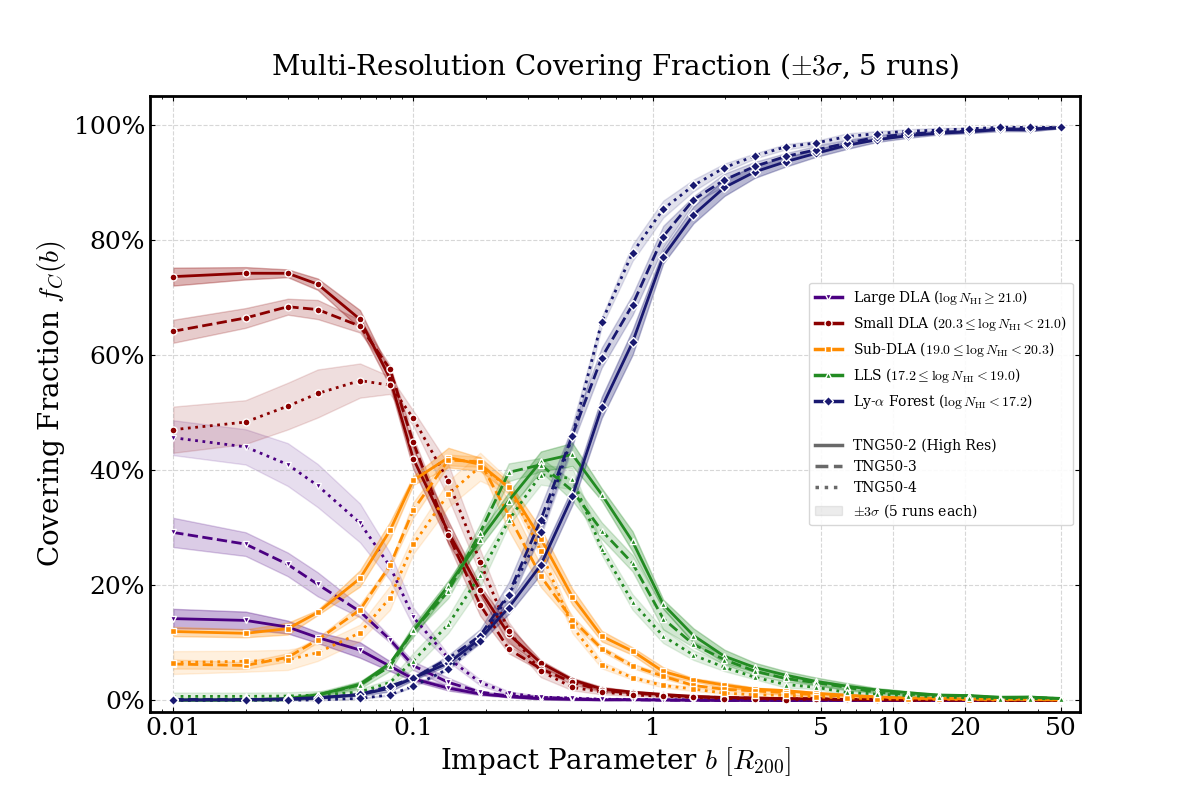

In [4]:
# Cell 2.5, the same plot, but without the grid panel
# ==============================================================================
# CELL 2b: COVERING FRACTION — MULTI-RESOLUTION, MAIN PANEL ONLY (no grid panel)
# ==============================================================================
# Reuses: NSIGMA, cat_styles, SIM_CONFIGS, sim_fractions, alpha_map (from Cell 2)

fig_cov_solo, ax_main = plt.subplots(figsize=(12, 8))

# ---- Main panel: profiles ----
for cat, cstyle in cat_styles.items():
    for sim_name, cfg in SIM_CONFIGS.items():
        if sim_name not in sim_fractions:
            continue

        radii = sim_fractions[sim_name]['radii']
        data  = sim_fractions[sim_name]['fracs'][cat]  # (n_runs, n_radii)

        mean_f = np.mean(data, axis=0)
        std_f  = np.std(data, axis=0)

        ls = cfg['ls']
        shade_alpha = alpha_map.get(sim_name, 0.07)

        # Only positive radii for log scale
        mask   = radii > 0
        r_plot = radii[mask]
        m_plot = mean_f[mask]
        s_plot = std_f[mask]

        # ±Nσ shading
        ax_main.fill_between(
            r_plot,
            np.clip(m_plot - NSIGMA * s_plot, 0, None),
            np.clip(m_plot + NSIGMA * s_plot, None, 1),
            color=cstyle['color'], alpha=shade_alpha, zorder=1,
        )

        # Mean line
        ax_main.plot(
            r_plot, m_plot,
            color=cstyle['color'], lw=2.0, ls=ls,
            marker=cstyle['marker'], ms=5, mec='white', zorder=3,
        )

# ---- Aesthetics ----
ax_main.grid(True, ls='--', alpha=0.5)
ax_main.set_xscale('log')
ax_main.set_ylim(-0.02, 1.05)
ax_main.set_xlim(0.008, 60)
ax_main.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0))

ax_main.set_xticks([0.01, 0.1, 1.0, 5.0, 10.0, 20.0, 50.0])
ax_main.set_xticklabels(['0.01', '0.1', '1', '5', '10', '20', '50'])

ax_main.set_xlabel(r'Impact Parameter $b \ [R_{200}]$')
ax_main.set_ylabel(r'Covering Fraction $f_C(b)$')
ax_main.set_title(
    rf'Multi-Resolution Covering Fraction ($\pm{NSIGMA}\sigma$, 5 runs)',
    pad=15,
)

# ---- Composite legend ----
legend_cat = [
    Line2D([0], [0], color=c['color'], lw=2.5, marker=c['marker'],
           ms=5, mec='white', label=c['label'])
    for c in cat_styles.values()
]
legend_cat.append(Line2D([0], [0], color='none', label=' '))

legend_sim = [
    Line2D([0], [0], color='dimgray', lw=2.5, ls=cfg['ls'],
           label=cfg['label'])
    for sim_name, cfg in SIM_CONFIGS.items()
    if sim_name in sim_data
]

legend_sim.append(
    patches.Patch(facecolor='gray', alpha=0.15, edgecolor='gray',
                  label=rf'$\pm {NSIGMA}\sigma$ (5 runs each)')
)

ax_main.legend(
    handles=legend_cat + legend_sim, loc='center right',
    frameon=True, fontsize=10, edgecolor='lightgray',
    facecolor='white', framealpha=0.9,
)

plt.show()

Ridgeline impact parameters (18): [0.0, 0.01, 0.02, 0.03, 0.04, 0.06, 0.08, 0.1, 0.14, 0.19, 0.25, 0.34, 0.46, 0.61, 0.82, 1.1, 1.47, 1.98]


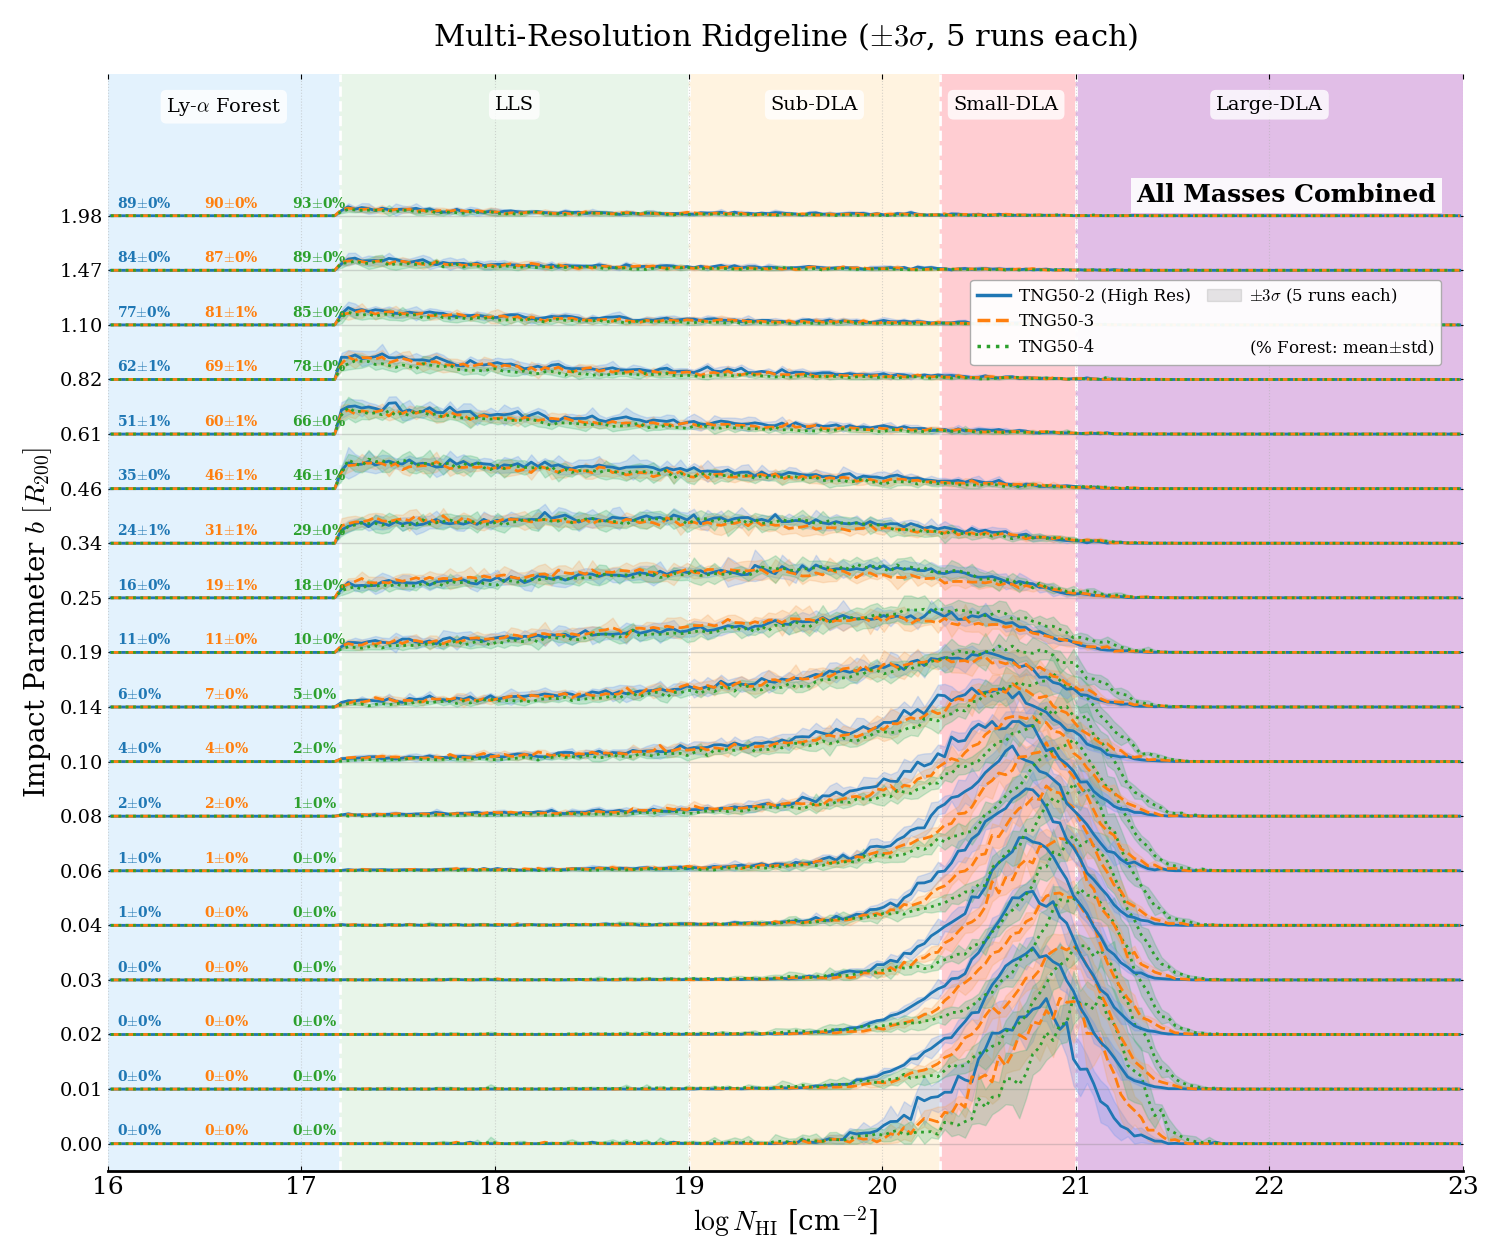

In [5]:
# ==============================================================================
# CELL 3: RIDGELINE — ALL SIMULATIONS, ALL MASSES COMBINED (DENSITY-NORMALIZED)
# ==============================================================================
# Background colours
c_forest   = '#E3F2FD'
c_lls      = '#E8F5E9'
c_subdla   = '#FFF3E0'
c_smalldla = '#FFCDD2'
c_largedla = '#E1BEE7'

# ----------------------------------------------------------------------------
# overlap_factor: COSMETIC VERTICAL SCALING.
# Each ridgeline curve is drawn above an integer y-base. The natural scale of
# the probability density (per dex) is typically small (~0.5-2.0), so we
# multiply by overlap_factor to make curves visually prominent.
#
# This does NOT distort the relative areas/heights within or across curves:
# - The AREA under the curve between two N_HI limits equals the FRACTION of
#   skewers falling in that range.
# - A larger overlap_factor just stretches all heights uniformly.
#
# Typical good values: 2.0 - 4.0. Bigger = more overlap between rows.
# ----------------------------------------------------------------------------
overlap_factor = 1.8
NSIGMA_RIDGE   = 3    # 1 standard deviation

# Histogram definitions (restricted to 16.0 -> 23.0)
num_bins  = 200
hist_bins = np.linspace(16.0, 23.0, num_bins + 1)
x_hist    = (hist_bins[:-1] + hist_bins[1:]) / 2
bin_width = hist_bins[1] - hist_bins[0]   # constant since we use linspace

# Sim-level colours and styles for ridgeline
SIM_RIDGE_STYLES = {
    'TNG50-2': {'color': 'tab:blue',   'fill': 'cornflowerblue', 'ls': '-'},
    'TNG50-3': {'color': 'tab:orange', 'fill': 'sandybrown',     'ls': '--'},
    'TNG50-4': {'color': 'tab:green',  'fill': 'mediumseagreen', 'ls': ':'},
}

# --------------------------------------------------------------------------
# CORRECTED HISTOGRAM: density per dex (dn / d log N_HI / N_total)
# --------------------------------------------------------------------------
def density_hist(values, bins, tot_skewers):
    """
    Returns a probability density per unit log N_HI.
    
    Height in each bin = (counts_in_bin / total_skewers) / bin_width
    
    Properties:
    - Integral over the entire range = fraction of skewers with valid log_n_hi
      (i.e., excluding forest sightlines with log_n_hi <= 1).
    - Integral over any sub-range [a, b] = fraction of skewers with log N_HI in [a, b].
    - Comparable between distributions and across simulations.
    
    Parameters
    ----------
    values : 1D array of log N_HI values (already filtered to the valid range).
    bins   : histogram bin edges.
    tot_skewers : total number of skewers at this (b, mass) cell, INCLUDING
                  forest sightlines. This is the denominator for normalization,
                  ensuring the visual matches the covering-fraction percentages.
    """
    if len(values) < 2 or tot_skewers == 0:
        return np.zeros(len(bins) - 1)
    
    counts, _ = np.histogram(values, bins=bins)
    bw = bins[1] - bins[0]
    return counts / (tot_skewers * bw)


def paint_ridgeline_multi(ax, sim_data, selected_b, mass_low=None, mass_high=None,
                          title_text='', show_legend=True):
    """
    Ridgeline overlaid using DENSITY-PER-DEX-normalized histograms.
    Heights are proportional to (fraction of total skewers per dex of log N_HI),
    so visual areas correspond faithfully to category populations.
    """
    # Background spans
    ax.axvspan(16.0, 17.2, color=c_forest,   zorder=0)
    ax.axvspan(17.2, 19.0, color=c_lls,      zorder=0)
    ax.axvspan(19.0, 20.3, color=c_subdla,   zorder=0)
    ax.axvspan(20.3, 21.0, color=c_smalldla, zorder=0)
    ax.axvspan(21.0, 23.0, color=c_largedla, zorder=0)

    # Threshold markers
    for xv in [17.2, 19.0, 20.3, 21.0]:
        ax.axvline(xv, color='white', ls='--', lw=2.0, zorder=0)

    # Regime Text Boxes at the top
    text_y_pos = 0.98
    bbox_props = dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8, edgecolor="none")
    ax.text(16.60, text_y_pos, r'Ly-$\alpha$ Forest', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=14, bbox=bbox_props, zorder=10)
    ax.text(18.10, text_y_pos, 'LLS', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=14, bbox=bbox_props, zorder=10)
    ax.text(19.65, text_y_pos, 'Sub-DLA', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=14, bbox=bbox_props, zorder=10)
    ax.text(20.64, text_y_pos, 'Small-DLA', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=14, bbox=bbox_props, zorder=10)
    ax.text(22.0, text_y_pos, 'Large-DLA', transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontsize=14, bbox=bbox_props, zorder=10)

    ax.grid(axis='x', ls=':', alpha=0.5)
    ax.grid(axis='y', visible=False)
    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

    y_ticks  = []
    y_labels = []

    for i_b, b_val in enumerate(selected_b):
        b_round = np.round(b_val, 2)
        y_base  = i_b

        y_ticks.append(y_base)
        y_labels.append(f"{b_val:.2f}")
        ax.axhline(y_base, color='gray', lw=1.0, alpha=0.3, zorder=1)

        text_offset = 0

        for sim_name, runs in sim_data.items():
            sty = SIM_RIDGE_STYLES.get(sim_name, {'color': 'black', 'fill': 'gray', 'ls': '-'})

            hist_stack  = []
            forest_pcts = []

            for df_run in runs:
                if mass_low is not None and mass_high is not None:
                    df_mass = df_run[
                        (df_run['halo_mass_msun'] >= mass_low) &
                        (df_run['halo_mass_msun'] <  mass_high)
                    ]
                else:
                    df_mass = df_run

                df_b  = df_mass[df_mass['r_mult_round'] == b_round]
                tot   = len(df_b)
                valid = df_b[df_b['log_n_hi'] > 1.0]['log_n_hi'].values

                # Density per dex, normalized by TOTAL skewers (including forest)
                mask_hist = (valid >= 16.0) & (valid <= 23.0)
                hist_dens = density_hist(valid[mask_hist], hist_bins, tot)
                hist_stack.append(hist_dens)

                if tot > 0:
                    pct_all = len(df_b[df_b['log_n_hi'] < 17.2]) / tot * 100
                else:
                    pct_all = 0.0

                forest_pcts.append(pct_all)

            hist_stack = np.array(hist_stack)

            mean_hist = np.mean(hist_stack, axis=0)
            std_hist  = np.std(hist_stack, axis=0)

            mean_scaled = mean_hist * overlap_factor
            lo_scaled   = np.clip(mean_hist - NSIGMA_RIDGE * std_hist, 0, None) * overlap_factor
            hi_scaled   = (mean_hist + NSIGMA_RIDGE * std_hist) * overlap_factor

            # σ band
            ax.fill_between(
                x_hist, y_base + lo_scaled, y_base + hi_scaled,
                color=sty['fill'], alpha=0.25, zorder=i_b + 3,
            )

            # Mean line
            ax.plot(
                x_hist, y_base + mean_scaled,
                color=sty['color'], lw=2.0, ls=sty['ls'], zorder=i_b + 5,
            )

            # Forest fraction annotation
            mean_f = np.mean(forest_pcts)
            std_f  = np.std(forest_pcts)
            
            ax.text(
                16.05 + text_offset * 0.9, y_base + 0.15,
                rf"{mean_f:.0f}$\pm${std_f:.0f}%",
                color=sty['color'], fontsize=10, fontweight='bold', zorder=20,
            )
            text_offset += 0.5

    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels, fontsize=14)
    ax.set_xlim(16.0, 23.0)
    ax.set_ylim(-0.5, len(selected_b) - 1 + overlap_factor + 0.8)

    if title_text:
        ax.text(
            0.98, 0.90, title_text, transform=ax.transAxes,
            fontsize=18, ha='right', va='top', fontweight='bold',
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='none'),
            zorder=30,
        )

    if show_legend:
        sim_lines = []
        for sim_name in sim_data.keys():
            sty = SIM_RIDGE_STYLES.get(sim_name, {'color': 'black', 'fill': 'gray', 'ls': '-'})
            lbl = SIM_CONFIGS.get(sim_name, {}).get('label', sim_name)
            sim_lines.append(
                Line2D([0], [0], color=sty['color'], lw=2.5, ls=sty['ls'], label=lbl)
            )

        band_patch = patches.Patch(
            facecolor='gray', alpha=0.2, edgecolor='gray',
            label=rf'$\pm {NSIGMA_RIDGE}\sigma$ (5 runs each)',
        )
        spacer = Line2D([0], [0], marker='none', linestyle='none', label=' ')
        info_line = Line2D([0], [0], marker='none', linestyle='none',
                           label=r'(% Forest: mean$\pm$std)')

        all_handles = sim_lines + [band_patch, spacer, info_line]

        leg = ax.legend(
            handles=all_handles, loc='upper right', ncol=2,
            frameon=True, fontsize=12,
            bbox_to_anchor=(0.99, 0.82),
            facecolor='white', framealpha=0.95,
            edgecolor='darkgray', columnspacing=1.0, handletextpad=0.5,
        )
        leg.set_zorder(100)


# --- Filter impact parameters: include 0.0, keep up to 2.0 R200 ---
SELECTED_B = sorted([b for b in ref_radii if 0.0 <= b <= 2.0])
n_sel = len(SELECTED_B)
print(f"Ridgeline impact parameters ({n_sel}): {SELECTED_B}")

# --- Plot: All Masses Combined ---
fig_height = max(10, 0.70 * n_sel)
fig_ridge_all, ax_ridge_all = plt.subplots(figsize=(15, fig_height))

paint_ridgeline_multi(
    ax_ridge_all, sim_data, SELECTED_B,
    mass_low=None, mass_high=None,
    title_text='All Masses Combined',
    show_legend=True,
)

ax_ridge_all.set_xlabel(r"$\log N_{\rm HI}$ [cm$^{-2}$]", fontsize=20)
ax_ridge_all.set_ylabel(r'Impact Parameter $b \ [R_{200}]$', fontsize=20)
ax_ridge_all.set_title(
    rf'Multi-Resolution Ridgeline ($\pm{NSIGMA_RIDGE}\sigma$, 5 runs each)',
    pad=20, fontsize=22,
)

plt.tight_layout()
plt.show()


In [6]:
# ==============================================================================
# OPTIONAL: SANITY-CHECK — verify visual areas match covering-fraction percentages
# ==============================================================================
print("\n" + "="*90)
print("SANITY CHECK: Integrating ridgeline density vs. raw category counts")
print("="*90)

check_b = 0.01  # change to inspect other impact parameters
print(f"\nAt b = {check_b} R200:\n")

for sim_name, runs in sim_data.items():
    sim_counts = {'Large_DLA': 0, 'Small_DLA': 0, 'Sub_DLA': 0, 'LLS': 0, 'Forest': 0}
    sim_total = 0
    for df_run in runs:
        df_b = df_run[df_run['r_mult_round'] == np.round(check_b, 2)]
        nhi = df_b['log_n_hi'].values
        sim_total += len(nhi)
        sim_counts['Large_DLA'] += np.sum(nhi >= 21.0)
        sim_counts['Small_DLA'] += np.sum((nhi >= 20.3) & (nhi < 21.0))
        sim_counts['Sub_DLA']   += np.sum((nhi >= 19.0) & (nhi < 20.3))
        sim_counts['LLS']       += np.sum((nhi >= 17.2) & (nhi < 19.0))
        sim_counts['Forest']    += np.sum(nhi < 17.2)
    
    if sim_total == 0:
        continue
    print(f"--- {sim_name}  (total = {sim_total} sightlines) ---")
    for cat, n in sim_counts.items():
        print(f"  {cat:<10s}: {n:5d}  ({100*n/sim_total:5.1f}%)")
    print()

print("Check: Large-DLA % from this table should match the height & width product")
print("       (i.e., integrated area) under the curve in the purple region.")
print("="*90)


SANITY CHECK: Integrating ridgeline density vs. raw category counts

At b = 0.01 R200:

--- TNG50-2  (total = 76440 sightlines) ---
  Large_DLA : 10870  ( 14.2%)
  Small_DLA : 56280  ( 73.6%)
  Sub_DLA   :  9161  ( 12.0%)
  LLS       :    56  (  0.1%)
  Forest    :    73  (  0.1%)

--- TNG50-3  (total = 76440 sightlines) ---
  Large_DLA : 22312  ( 29.2%)
  Small_DLA : 49025  ( 64.1%)
  Sub_DLA   :  4841  (  6.3%)
  LLS       :   128  (  0.2%)
  Forest    :   134  (  0.2%)

--- TNG50-4  (total = 76440 sightlines) ---
  Large_DLA : 34890  ( 45.6%)
  Small_DLA : 35957  ( 47.0%)
  Sub_DLA   :  5036  (  6.6%)
  LLS       :   539  (  0.7%)
  Forest    :    18  (  0.0%)

Check: Large-DLA % from this table should match the height & width product
       (i.e., integrated area) under the curve in the purple region.


In [ ]:
# ==============================================================================
# CELL 4: RIDGELINE — SPLIT BY MASS BIN
# ==============================================================================
mass_edges_ridge = [10**10.0, 10**10.5, 10**11.0, 10**11.5, 10**12.0, 10**13.0]
mass_labels_ridge = [
    r'$10^{10.0} \leq M_{200} < 10^{10.5} \; M_\odot$',
    r'$10^{10.5} \leq M_{200} < 10^{11.0} \; M_\odot$',
    r'$10^{11.0} \leq M_{200} < 10^{11.5} \; M_\odot$',
    r'$10^{11.5} \leq M_{200} < 10^{12.0} \; M_\odot$',
    r'$10^{12.0} \leq M_{200} < 10^{13.0} \; M_\odot$',
]
n_mass_bins = len(mass_labels_ridge)

fig_height_bin = max(8, 0.70 * n_sel)
fig_ridge_mass, axes_ridge_mass = plt.subplots(
    n_mass_bins, 1,
    figsize=(15, fig_height_bin * n_mass_bins),
    sharex=True,
)
if n_mass_bins == 1:
    axes_ridge_mass = np.array([axes_ridge_mass])

for i_m in range(n_mass_bins):
    m_low  = mass_edges_ridge[i_m]
    m_high = mass_edges_ridge[i_m + 1]

    paint_ridgeline_multi(
        axes_ridge_mass[i_m], sim_data, SELECTED_B,
        mass_low=m_low, mass_high=m_high,
        title_text=mass_labels_ridge[i_m],
        show_legend=(i_m == 0),
    )

axes_ridge_mass[-1].set_xlabel(r"$\log N_{\rm HI}$ [cm$^{-2}$]", fontsize=20)
fig_ridge_mass.text(
    0.015, 0.5,
    r'Impact Parameter $b \ [R_{200}]$',
    va='center', rotation='vertical', fontsize=22,
)
fig_ridge_mass.suptitle(
    rf'Multi-Resolution Ridgeline by Mass Bin '
    rf'($\pm{NSIGMA_RIDGE}\sigma$, 5 runs each)',
    fontsize=24, y=1.001,
)

plt.tight_layout(rect=[0.03, 0.0, 1, 1])
plt.show()

In [ ]:
# ==============================================================================
# CELL 5: SUMMARY TABLES
# ==============================================================================

# Read redshift from data
z_ref = list(sim_data.values())[0][0].iloc[0]['redshift'] \
        if 'redshift' in list(sim_data.values())[0][0].columns else 3.0
a_ref = 1.0 / (1.0 + z_ref)

# ══════════════════════════════════════════════════════════════════════════
# TABLE 1: ABSORBER FRACTIONS AT MAXIMUM IMPACT PARAMETER
# ══════════════════════════════════════════════════════════════════════════
print("\n" + "=" * 110)
print(f"  TABLE 1 — ABSORBER FRACTIONS AT MAXIMUM IMPACT PARAMETER  (mean ± 1σ, 5 runs)")
print("=" * 110)

header = (f"{'Simulation':<22} | {'b_max':>6} | {'L-DLA':>12} | {'S-DLA':>12} "
          f"| {'Sub-DLA':>12} | {'LLS':>12} | {'Forest':>12}")
print(header)
print("-" * 110)

for sim_name, runs in sim_data.items():
    radii = np.sort(runs[0]['r_mult_round'].unique())
    max_b = radii[radii > 0].max()

    pcts_all = []
    for df_run in runs:
        df_b = df_run[df_run['r_mult_round'] == np.round(max_b, 2)]
        tot  = len(df_b)
        if tot > 0:
            nhi = df_b['log_n_hi']
            pcts_all.append([
                len(nhi[nhi >= 21.0]) / tot * 100,
                len(nhi[(nhi >= 20.3) & (nhi < 21.0)]) / tot * 100,
                len(nhi[(nhi >= 19.0) & (nhi < 20.3)]) / tot * 100,
                len(nhi[(nhi >= 17.2) & (nhi < 19.0)]) / tot * 100,
                len(nhi[nhi < 17.2]) / tot * 100,
            ])

    arr   = np.array(pcts_all)
    means = np.mean(arr, axis=0)
    stds  = np.std(arr, axis=0)

    lbl = SIM_CONFIGS[sim_name]['label']
    row = f"{lbl:<22} | {max_b:>5.1f} "
    for m, s in zip(means, stds):
        row += f"| {m:>5.1f}±{s:>4.1f}% "
    print(row)

print("=" * 110)


# ══════════════════════════════════════════════════════════════════════════
# TABLE 2: LARGEST HALO R200 IN EACH SIMULATION
# ══════════════════════════════════════════════════════════════════════════
print("\n" + "=" * 105)
print(f"  TABLE 2 — LARGEST HALO R200 IN EACH SIMULATION  (run 0, z = {z_ref:.2f})")
print("=" * 105)
print(f"{'Simulation':<22} | {'Halo ID':>10} | {'M200 [M☉]':>16} | "
      f"{'R200 [ckpc/h]':>14} | {'R200 [pkpc]':>12} | {'R200 [pMpc]':>12}")
print("-" * 105)

for sim_name, runs in sim_data.items():
    df0 = runs[0].drop_duplicates(subset=['halo_id']).copy()
    idx_max = df0['halo_mass_msun'].idxmax()
    row_max = df0.loc[idx_max]

    halo_id   = int(row_max['halo_id'])
    mass_msun = row_max['halo_mass_msun']
    raw_r200  = row_max['halo_r200_mpc']

    if raw_r200 > 10:
        r200_ckpch = raw_r200
    else:
        r200_ckpch = raw_r200 * 1e3

    r200_pkpc = r200_ckpch / HUBBLE_H * a_ref
    r200_pmpc = r200_pkpc / 1e3

    lbl = SIM_CONFIGS[sim_name]['label']
    print(f"{lbl:<22} | {halo_id:>10d} | {mass_msun:>16.4e} | "
          f"{r200_ckpch:>14.2f} | {r200_pkpc:>12.2f} | {r200_pmpc:>12.6f}")

print("=" * 105 + "\n")


# ══════════════════════════════════════════════════════════════════════════
# TABLE 3: FOREST FRACTION AT ALL IMPACT PARAMETERS
# ══════════════════════════════════════════════════════════════════════════
print("\n" + "=" * 100)
print(f"  TABLE 3 — FOREST FRACTION (log NHI < 17.2) AT SELECTED IMPACT PARAMETERS")
print("=" * 100)

header = f"{'b [R200]':>10}"
for sim_name in sim_data.keys():
    lbl = SIM_CONFIGS[sim_name]['label'].split(' ')[0]
    header += f" | {lbl:>12}"
print(header)
print("-" * 100)

for b_val in SELECTED_B:
    b_round = np.round(b_val, 2)
    row = f"{b_val:>10.2f}"

    for sim_name, runs in sim_data.items():
        pcts = []
        for df_run in runs:
            df_b = df_run[df_run['r_mult_round'] == b_round]
            tot  = len(df_b)
            if tot > 0:
                p = len(df_b[df_b['log_n_hi'] < 17.2]) / tot * 100
            else:
                p = np.nan
            pcts.append(p)

        arr = np.array(pcts)
        row += f" | {np.nanmean(arr):>6.1f}±{np.nanstd(arr):>4.1f}%"
        
    print(row)

print("=" * 100 + "\n")

In [3]:
from fake_spectra import gas_properties, spectra